# Módulo 12 — Monte Carlo: discretização e redução de variância

**Curso:** Derivativos com Python, a partir de *Derivatives Analytics with Python* (Y. Hilpisch, Wiley, 2015).
**Este módulo cobre:** capítulo 10 do livro.

## O que você vai conseguir fazer ao final

1. Distinguir erro forte de erro fraco e medir a ordem de convergência de um esquema de Euler.
2. Deduzir a transição exata do processo de raiz quadrada (CIR) e simulá-la com qui-quadrados.
3. Avaliar títulos zero-cupom no CIR por Monte Carlo e separar viés de discretização de ruído.
4. Conhecer os esquemas de Euler para a variância de Heston e saber quais deles são, de fato, diferentes.
5. Encontrar, medir e explicar um viés de "olhar para a frente" no código do livro.
6. Usar variáveis antitéticas, casamento de momentos e variáveis de controle, sabendo o que cada uma corrige.
7. Avaliar puts americanas no modelo Heston com juros CIR por LSM com variável de controle.

## Onde estamos

Até aqui, quase todo preço europeu veio de fórmulas: BSM no Módulo 5, Fourier nos Módulos 7, 8, 10 e 11. O Monte Carlo apareceu no Módulo 9, para as americanas, num mundo BSM em que a simulação de $S$ era exata.

Agora o mundo é o do Módulo 11: variância e juros seguem processos de raiz quadrada. Simular exige **discretizar**, e discretizar introduz erros que não diminuem com mais trajetórias. Este módulo trata dessas duas fontes de erro, a de discretização (viés) e a estatística (ruído), e das técnicas para reduzir cada uma.

## 0. Preparação

Além do ambiente padrão, a célula traz três ferramentas dos módulos anteriores:

* a função característica de Heston na forma estável e o preço de Lewis (Módulos 7 e 11), que servem de referência "exata";
* o preço do título zero-cupom no CIR (Módulo 11);
* o critério de acurácia do livro: um preço está certo se o erro absoluto for menor que 2,5 centavos **ou** o erro relativo for menor que 1,5%.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import simpson, solve_ivp
from scipy.stats import norm, ncx2, kstest
from IPython.display import display

AZUL, LARANJA, VERDE, CINZA = "#2a78d6", "#eb6834", "#1baf7a", "#8a8a84"
RAMPA = ["#86b6ef", "#2a78d6", "#104281"]

plt.rcParams.update({
    "figure.figsize": (7.2, 4.0), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5df", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "lines.linewidth": 2.0, "legend.frameon": False,
    "font.size": 10,
})


def f3(x):
    """Formata com três casas decimais no padrão brasileiro."""
    return f"{x:,.3f}".replace(",", "§").replace(".", ",").replace("§", ".")


def tabela(df):
    """Exibe um DataFrame com os números reais em três casas decimais."""
    def fmt(v):
        if isinstance(v, (float, np.floating)):
            return "n/d" if np.isnan(v) else f3(v)
        return v
    display(df.map(fmt))


_checks = {"n": 0}


def ok(condicao, mensagem):
    """Verificação do laboratório: interrompe o notebook se a conta não fechar."""
    assert bool(condicao), f"FALHOU: {mensagem}"
    _checks["n"] += 1
    print(f"OK — {mensagem}")


def bsm(S, K, T, r, sig):
    d1 = (np.log(S / K) + (r + 0.5 * sig**2) * T) / (sig * np.sqrt(T))
    return S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d1 - sig * np.sqrt(T))


def cf_heston(u, T, v0, kappa, theta, sigma, rho):
    """Função característica de ln(S_T/S_0) - rT no Heston, forma estável."""
    xi = kappa - rho * sigma * 1j * u
    d = np.sqrt(xi**2 + sigma**2 * (1j * u + u**2))
    g = (xi - d) / (xi + d)
    e = np.exp(-d * T)
    A = kappa * theta / sigma**2 * ((xi - d) * T - 2 * np.log((1 - g * e) / (1 - g)))
    B = (xi - d) / sigma**2 * (1 - e) / (1 - g * e)
    return np.exp(A + B * v0)


_U = np.linspace(0, 300, 30001)


def call_heston(K, T, r, v0, kappa, theta, sigma, rho, S0=100.0):
    """Call europeia de Heston pela fórmula de Lewis (vetorizada em K)."""
    K = np.atleast_1d(np.asarray(K, float))
    k = np.log(S0 / K) + r * T
    h = np.exp(1j * _U * k[:, None]) * cf_heston(_U - 0.5j, T, v0, kappa, theta, sigma, rho)
    integral = simpson(h.real / (_U**2 + 0.25), x=_U, axis=1)
    return S0 - np.sqrt(S0 * K) * np.exp(-0.5 * r * T) / np.pi * integral


def zcb_cir(r0, kappa, theta, sigma, tau):
    """Preço do zero-cupom no CIR (Módulo 11)."""
    g = np.sqrt(kappa**2 + 2 * sigma**2)
    e = np.exp(g * tau) - 1
    den = 2 * g + (kappa + g) * e
    A = (2 * g * np.exp((kappa + g) * tau / 2) / den) ** (2 * kappa * theta / sigma**2)
    return A * np.exp(-2 * e / den * r0)


def acerto(erro, ref, abs_tol=0.025, rel_tol=0.015):
    """Critério do livro: certo se |erro| < 2,5 centavos ou |erro| < 1,5% do preço."""
    erro, ref = np.asarray(erro), np.asarray(ref)
    return (np.abs(erro) < abs_tol) | (np.abs(erro) < rel_tol * np.abs(ref))


print("Ambiente pronto.")

Ambiente pronto.


---
## 1. Discretizar uma equação diferencial estocástica

**Livro: §10.1 e §10.3 (equações 10.6 e 10.7)**

### 1.1 O esquema de Euler, passo a passo

Considere $dX_t = a(X_t)\,dt + b(X_t)\,dW_t$. Dividimos $[0, T]$ em $M$ passos de tamanho $\Delta t = T/M$. Num passo de $s$ a $t = s + \Delta t$, a solução é

$$X_t = X_s + \int_s^t a(X_u)\,du + \int_s^t b(X_u)\,dW_u.$$

Euler congela os coeficientes no **início** do passo, $a(X_u) \approx a(X_s)$ e $b(X_u) \approx b(X_s)$:

$$X_t \approx X_s + a(X_s)\,\Delta t + b(X_s)\,(W_t - W_s) = X_s + a(X_s)\,\Delta t + b(X_s)\sqrt{\Delta t}\,z, \qquad z \sim N(0,1).$$

Repare no detalhe que vai importar na Seção 4: o coeficiente $b$ é avaliado em $X_s$, um valor **conhecido** antes do choque $z$. É isso que faz a integral estocástica de Itô ter média zero: $\mathbb{E}[b(X_s)\,z] = \mathbb{E}[b(X_s)]\,\mathbb{E}[z] = 0$, porque $z$ é independente do passado.

### 1.2 Dois tipos de erro

Seja $\hat X_T$ o valor simulado e $X_T$ o verdadeiro, ambos com o mesmo browniano.

* **Erro forte**: $\mathbb{E}\,|\hat X_T - X_T|$. Mede se as *trajetórias* estão certas. Para Euler, cai como $\Delta t^{1/2}$.
* **Erro fraco**: $|\mathbb{E}[f(\hat X_T)] - \mathbb{E}[f(X_T)]|$. Mede se as *distribuições* estão certas. Para Euler, cai como $\Delta t^{1}$.

Para preço de opção europeia, só o erro fraco interessa: queremos a média do payoff. O erro fraco é um **viés**: ele não diminui com mais trajetórias, só com mais passos.

### 1.3 Três esquemas para o índice

Para $dS = rS\,dt + \sigma S\,dW$ há três escolhas naturais:

| Esquema | Passo | Observação |
|---|---|---|
| Euler clássico | $S_t = S_s(1 + r\Delta t + \sigma\sqrt{\Delta t}\,z)$ | média $(1+r\Delta t)$, não $e^{r\Delta t}$ |
| Ingênuo (10.7) | $S_t = S_s(e^{r\Delta t} + \sigma\sqrt{\Delta t}\,z)$ | média certa, distribuição normal no passo |
| Log-Euler (10.6) | $S_t = S_s\exp\!\big((r - \tfrac12\sigma^2)\Delta t + \sigma\sqrt{\Delta t}\,z\big)$ | exato para $\sigma$ constante |

O log-Euler vem de aplicar Itô a $\ln S$ (Módulo 4): $d\ln S = (r - \tfrac12\sigma^2)dt + \sigma\,dW$, uma equação de coeficientes constantes, que Euler integra sem erro. Com volatilidade estocástica ele deixa de ser exato, mas continua sendo o melhor ponto de partida.

### Laboratório 1 — A ordem do erro fraco

Usamos uma call fora do dinheiro ($K = 130$), em que o viés é mais visível. Para medir um viés de poucos centavos sem que o ruído o encubra, usamos **números aleatórios comuns**: geramos os incrementos brownianos numa grade fina e os somamos para as grades grossas. Assim, todos os esquemas veem o mesmo $W_T$, e o log-Euler (exato) dá o payoff de referência trajetória a trajetória. A diferença média entre um esquema e a referência é o viés, com pouquíssimo ruído.

In [2]:
S0, K, r, sig, T = 100.0, 130.0, 0.05, 0.3, 1.0   # call fora do dinheiro
I, Mfino = 200_000, 64
rng = np.random.default_rng(12)
dW = rng.standard_normal((Mfino, I)) * np.sqrt(T / Mfino)
payoff_exato = np.maximum(S0 * np.exp((r - 0.5 * sig**2) * T + sig * dW.sum(0)) - K, 0)

linhas = []
for M in [1, 2, 4, 8, 16, 32, 64]:
    dt = T / M
    inc = dW.reshape(M, Mfino // M, I).sum(1)          # incrementos da grade grossa
    S_cl = S0 * np.prod(1 + r * dt + sig * inc, axis=0)
    S_in = S0 * np.prod(np.exp(r * dt) + sig * inc, axis=0)
    vies_cl = np.exp(-r * T) * np.mean(np.maximum(S_cl - K, 0) - payoff_exato)
    vies_in = np.exp(-r * T) * np.mean(np.maximum(S_in - K, 0) - payoff_exato)
    linhas.append((M, dt, vies_cl, vies_in))
tab1 = pd.DataFrame(linhas, columns=["M", "Δt", "viés Euler clássico", "viés ingênuo (10.7)"])
tabela(tab1)
print("preço exato BSM:", f3(bsm(S0, K, T, r, sig)),
      "| média MC do log-Euler:", f3(np.exp(-r * T) * payoff_exato.mean()))

,M,Δt,viés Euler clássico,viés ingênuo (10.7)
0,1,"1,000","-1,425","-1,400"
1,2,"0,500","-0,681","-0,666"
2,4,"0,250","-0,318","-0,309"
3,8,"0,125","-0,156","-0,151"
4,16,"0,062","-0,079","-0,077"
5,32,"0,031","-0,039","-0,037"
6,64,"0,016","-0,019","-0,018"


preço exato BSM: 4,673 | média MC do log-Euler: 4,633


A tabela mostra o viés caindo pela metade quando $M$ dobra: é a assinatura da ordem 1. Vamos estimá-la pela inclinação em escala log-log, usando $M \ge 4$ (para $M$ muito pequeno, termos de ordem superior ainda pesam).

ordem estimada — clássico: 1,015 | ingênuo: 1,016


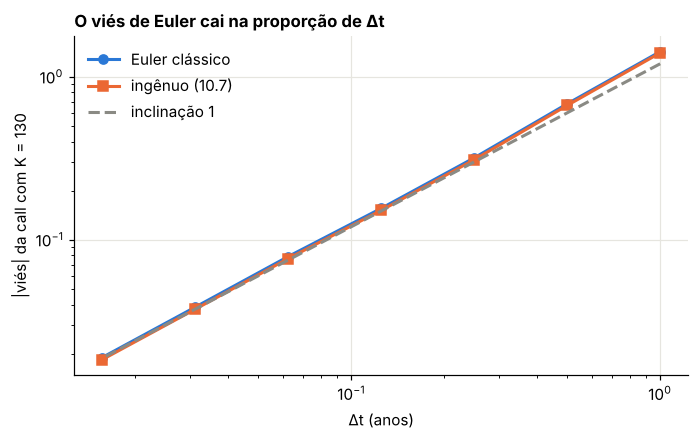

OK — o erro fraco do Euler clássico tem ordem 1
OK — o erro fraco do esquema ingênuo também tem ordem 1
OK — o log-Euler com σ constante reproduz o BSM, a menos do ruído


In [3]:
sel = tab1["M"] >= 4
p_cl = np.polyfit(np.log(tab1.loc[sel, "Δt"]), np.log(np.abs(tab1.loc[sel, "viés Euler clássico"])), 1)[0]
p_in = np.polyfit(np.log(tab1.loc[sel, "Δt"]), np.log(np.abs(tab1.loc[sel, "viés ingênuo (10.7)"])), 1)[0]
print("ordem estimada — clássico:", f3(p_cl), "| ingênuo:", f3(p_in))

fig, ax = plt.subplots()
ax.loglog(tab1["Δt"], np.abs(tab1["viés Euler clássico"]), "o-", color=AZUL, label="Euler clássico")
ax.loglog(tab1["Δt"], np.abs(tab1["viés ingênuo (10.7)"]), "s-", color=LARANJA, label="ingênuo (10.7)")
ax.loglog(tab1["Δt"], 1.2 * tab1["Δt"], "--", color=CINZA, label="inclinação 1")
ax.set_xlabel("Δt (anos)")
ax.set_ylabel("|viés| da call com K = 130")
ax.set_title("O viés de Euler cai na proporção de Δt")
ax.legend()
plt.show()

ok(0.8 < p_cl < 1.2, "o erro fraco do Euler clássico tem ordem 1")
ok(0.8 < p_in < 1.2, "o erro fraco do esquema ingênuo também tem ordem 1")
ok(abs(np.exp(-r * T) * payoff_exato.mean() - bsm(S0, K, T, r, sig)) < 0.1,
   "o log-Euler com σ constante reproduz o BSM, a menos do ruído")

**O que aprendemos.** Com 64 passos por ano o viés ainda é de cerca de 2 centavos numa call de uns 4,7, e sempre para baixo. O esquema ingênuo tem a média certa a cada passo, mas a distribuição errada; e o preço de uma opção depende da distribuição. A lição para o resto do módulo: **acertar a média de $S_T$ não garante acertar o preço**, e errar a média garante errar.

---
## 2. O processo de raiz quadrada: a transição exata

**Livro: §10.2**

O processo

$$dx_t = \kappa(\theta - x_t)\,dt + \sigma\sqrt{x_t}\,dZ_t \tag{10.1}$$

é a dinâmica dos juros no CIR e da variância no Heston. Ao contrário do caso geral, aqui a lei de $x_t$ dado $x_s$ é conhecida, e podemos simular sem erro de discretização.

### 2.1 Dedução pela estrutura afim

No Módulo 11, deduzimos o zero-cupom tentando $\exp(A + B\,x)$. Fazemos o mesmo com a função geradora de momentos. Seja $\tau = t - s$ e $w$ real com $1 - 2c(\tau)w > 0$. Procuramos

$$\mathbb{E}\big[e^{w x_t}\,\big|\,x_s\big] = \exp\big(A(\tau) + B(\tau)\,x_s\big).$$

**Passo 1 — as equações.** O lado esquerdo, como função de $(s, x_s)$, é uma martingal; por Feynman-Kac, satisfaz $-\partial_\tau F + \kappa(\theta - x)F_x + \tfrac12\sigma^2 xF_{xx} = 0$, com $F(0, x) = e^{wx}$. Substituindo a forma afim e separando os termos com $x$ dos sem $x$:

$$B' = -\kappa B + \tfrac12\sigma^2 B^2,\quad B(0) = w; \qquad A' = \kappa\theta B,\quad A(0) = 0.$$

**Passo 2 — resolver $B$.** É uma equação de Bernoulli. Com $u = 1/B$, temos $u' = -B'/B^2 = \kappa u - \tfrac12\sigma^2$, que é linear:

$$u(\tau) = \Big(\frac1w - \frac{\sigma^2}{2\kappa}\Big)e^{\kappa\tau} + \frac{\sigma^2}{2\kappa}
\quad\Longrightarrow\quad
B(\tau) = \frac{w\,e^{-\kappa\tau}}{1 - 2c\,w}, \qquad c \equiv \frac{\sigma^2(1 - e^{-\kappa\tau})}{4\kappa}.$$

**Passo 3 — resolver $A$.** Como $\tfrac{d}{d\tau}\ln(1 - 2cw) = -\tfrac{\sigma^2}{2}\,\tfrac{w e^{-\kappa\tau}}{1 - 2cw} = -\tfrac{\sigma^2}{2}B$, temos

$$A(\tau) = \kappa\theta\int_0^\tau B = -\frac{2\kappa\theta}{\sigma^2}\ln(1 - 2cw) = -\frac d2\ln(1 - 2cw), \qquad d \equiv \frac{4\kappa\theta}{\sigma^2}.$$

**Passo 4 — reconhecer a distribuição.** Juntando,

$$\mathbb{E}\big[e^{w x_t}\,\big|\,x_s\big] = (1 - 2cw)^{-d/2}\exp\!\Big(\frac{\lambda\,c\,w}{1 - 2cw}\Big), \qquad \lambda \equiv \frac{x_s\,e^{-\kappa\tau}}{c}.$$

A geradora de momentos de uma qui-quadrado não central $Y \sim \chi'^2_d(\lambda)$ é $\mathbb{E}[e^{vY}] = (1 - 2v)^{-d/2}\exp\big(\lambda v/(1 - 2v)\big)$. Com $v = cw$, as duas coincidem. Logo

$$\boxed{\;x_t = c\,Y, \qquad Y \sim \chi'^2_d(\lambda), \qquad c = \frac{\sigma^2(1 - e^{-\kappa\Delta t})}{4\kappa},\quad d = \frac{4\kappa\theta}{\sigma^2},\quad \lambda = \frac{4\kappa e^{-\kappa\Delta t}}{\sigma^2(1 - e^{-\kappa\Delta t})}\,x_s.\;}$$

É a fórmula do livro. Note que $d$ não depende de $\Delta t$, e que a condição de Feller $2\kappa\theta \ge \sigma^2$ é exatamente $d \ge 2$.

### 2.2 Como sortear uma qui-quadrado não central

O livro usa duas decomposições, que vêm direto da definição $\chi'^2_d(\lambda) = \sum_{j=1}^{d}(z_j + \mu_j)^2$ com $\sum\mu_j^2 = \lambda$:

* **Se $d > 1$:** ponha toda a não centralidade numa coordenada: $\chi'^2_d(\lambda) = (z + \sqrt\lambda)^2 + \chi^2_{d-1}$.
* **Se $d \le 1$** (aí $d - 1 \le 0$ não serve): use a mistura de Poisson $\chi'^2_d(\lambda) = \chi^2_{d + 2N}$, com $N \sim \text{Poisson}(\lambda/2)$.

Os dois primeiros momentos condicionais, que vamos conferir, são

$$\mathbb{E}[x_t\,|\,x_s] = \theta + (x_s - \theta)e^{-\kappa\Delta t}, \qquad
\text{Var}[x_t\,|\,x_s] = x_s\frac{\sigma^2 e^{-\kappa\Delta t}}{\kappa}(1 - e^{-\kappa\Delta t}) + \theta\frac{\sigma^2}{2\kappa}(1 - e^{-\kappa\Delta t})^2.$$

### Laboratório 2 — Conferir a transição exata

Três conferências: (a) a solução fechada de $B$ e $A$ contra a integração numérica das equações; (b) as duas decomposições contra os momentos teóricos; (c) a distribuição inteira contra a do SciPy, por um teste de Kolmogorov-Smirnov.

In [4]:
def cir_constantes(kappa, theta, sigma, dt):
    c = sigma**2 * (1 - np.exp(-kappa * dt)) / (4 * kappa)
    d = 4 * kappa * theta / sigma**2
    return c, d


def cir_exato_passo(x, kappa, theta, sigma, dt, rng):
    """Um passo exato do processo de raiz quadrada, pelas decomposições do livro."""
    c, d = cir_constantes(kappa, theta, sigma, dt)
    lam = x * np.exp(-kappa * dt) / c
    if d > 1:
        z = rng.standard_normal(x.shape)
        return c * ((z + np.sqrt(lam)) ** 2 + rng.chisquare(d - 1, x.shape))
    N = rng.poisson(lam / 2)
    return c * rng.chisquare(d + 2 * N)


# (a) Riccati numérica contra a solução fechada
kappa, theta, sigma, tau, w = 0.3, 0.04, 0.1, 2.0, 3.0
sol = solve_ivp(lambda t, y: [kappa * theta * y[1], -kappa * y[1] + 0.5 * sigma**2 * y[1] ** 2],
                [0, tau], [0.0, w], rtol=1e-11, atol=1e-13)
A_num, B_num = sol.y[:, -1]
c, d = cir_constantes(kappa, theta, sigma, tau)
B_fec = w * np.exp(-kappa * tau) / (1 - 2 * c * w)
A_fec = -d / 2 * np.log(1 - 2 * c * w)
print("B: numérico", f3(B_num), "fechado", f3(B_fec), "| A: numérico", f3(A_num), "fechado", f3(A_fec))
ok(abs(B_num - B_fec) < 1e-8 and abs(A_num - A_fec) < 1e-8, "a solução fechada da Riccati confere com a integração numérica")

# (b) e (c): momentos e distribuição, nos dois regimes de d
rng = np.random.default_rng(2)
casos = {"d > 1 (Feller vale)": (0.3, 0.04, 0.1), "d ≤ 1 (Feller falha)": (0.1, 0.03, 0.2)}
x_s, dt, n = 0.03, 0.25, 400_000
linhas = []
amostras = {}
for nome, (kappa, theta, sigma) in casos.items():
    c, d = cir_constantes(kappa, theta, sigma, dt)
    xt = cir_exato_passo(np.full(n, x_s), kappa, theta, sigma, dt, rng)
    e = np.exp(-kappa * dt)
    media = theta + (x_s - theta) * e
    var = x_s * sigma**2 * e / kappa * (1 - e) + theta * sigma**2 / (2 * kappa) * (1 - e) ** 2
    ks = kstest(xt[:20000] / c, ncx2(d, x_s * e / c).cdf).pvalue
    linhas.append((nome, d, xt.mean() * 100, media * 100, xt.std() * 100, np.sqrt(var) * 100, ks))
    amostras[nome] = (xt, c, d, x_s * e / c)
tab2 = pd.DataFrame(linhas, columns=["caso", "d", "média MC (%)", "média teórica (%)",
                                     "desvio MC (%)", "desvio teórico (%)", "p-valor KS"])
tabela(tab2)
for _, l in tab2.iterrows():
    ok(abs(l["média MC (%)"] / l["média teórica (%)"] - 1) < 0.005, f"{l['caso']}: a média confere")
    ok(abs(l["desvio MC (%)"] / l["desvio teórico (%)"] - 1) < 0.01, f"{l['caso']}: o desvio confere")
    ok(l["p-valor KS"] > 0.001, f"{l['caso']}: o teste KS não rejeita a qui-quadrado não central")

B: numérico 1,684 fechado 1,684 | A: numérico 0,055 fechado 0,055
OK — a solução fechada da Riccati confere com a integração numérica


,caso,d,média MC (%),média teórica (%),desvio MC (%),desvio teórico (%),p-valor KS
0,d > 1 (Feller vale),"4,800","3,074","3,072","0,840","0,840","0,243"
1,d ≤ 1 (Feller falha),"0,300","3,001","3,000","1,712","1,711","0,999"


OK — d > 1 (Feller vale): a média confere
OK — d > 1 (Feller vale): o desvio confere
OK — d > 1 (Feller vale): o teste KS não rejeita a qui-quadrado não central
OK — d ≤ 1 (Feller falha): a média confere
OK — d ≤ 1 (Feller falha): o desvio confere
OK — d ≤ 1 (Feller falha): o teste KS não rejeita a qui-quadrado não central


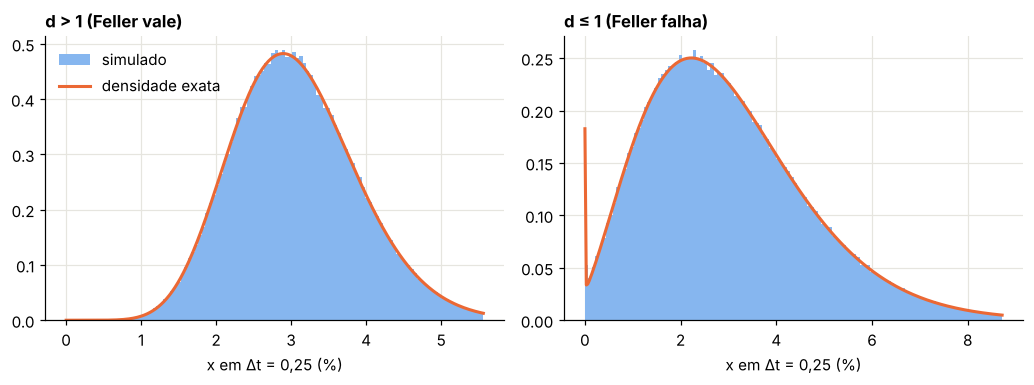

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(9.5, 3.6))
for ax, (nome, (xt, c, d, lam)) in zip(axs, amostras.items()):
    grade = np.linspace(1e-5, np.quantile(xt, 0.995), 300)
    ax.hist(xt * 100, bins=120, range=(0, grade[-1] * 100), density=True, color=RAMPA[0], label="simulado")
    ax.plot(grade * 100, ncx2(d, lam).pdf(grade / c) / c / 100, color=LARANJA, label="densidade exata")
    ax.set_title(nome)
    ax.set_xlabel("x em Δt = 0,25 (%)")
axs[0].legend()
plt.tight_layout()
plt.show()

Com $d \le 1$ (direita), a densidade explode em zero: o processo encosta no zero com frequência. É justamente o regime em que os esquemas de Euler sofrem, porque o $\sqrt{x}$ de um valor discretizado pode ficar negativo.

---
## 3. Zero-cupons no CIR por Monte Carlo

**Livro: §10.2 (Figuras 10.1 a 10.3)**

### 3.1 O estimador

Numa trajetória $i$ com grade $t_0 = 0 < t_1 < \dots < t_M = T$, descontamos o valor 1 de trás para a frente, com a regra do trapézio para a integral de $r$:

$$B_{t_{j},i} = B_{t_{j+1},i}\,\exp\!\Big(-\frac{r_{t_j,i} + r_{t_{j+1},i}}{2}\,\Delta t\Big), \qquad B_{T,i} = 1.$$

Em $t = 0$, a média $\frac1I\sum_i B_{0,i}$ estima $P(0, T)$, que conhecemos em forma fechada.

### 3.2 O que a média estima em $t > 0$

Em $t > 0$, cada $B_{t,i}$ estima o preço do zero-cupom **condicional** à taxa $r_{t,i}$ daquela trajetória. A média sobre trajetórias estima, portanto, $\mathbb{E}[P(r_t, T - t)]$.

O livro compara essa média com $P\big(\mathbb{E}[r_t], T - t\big)$. Como $P$ é convexa em $r$ ($P = e^{A - br}$), pela desigualdade de Jensen

$$\mathbb{E}[P(r_t, \tau)] \ge P(\mathbb{E}[r_t], \tau).$$

A referência certa pode ser calculada **exatamente** com o que deduzimos na Seção 2: $\mathbb{E}[e^{A - b\,r_t}] = e^{A}\,\mathbb{E}[e^{-b\,r_t}]$, e a esperança é a geradora de momentos da qui-quadrado não central em $w = -b$.

### 3.3 O esquema de Euler para comparação

O livro usa o **Full Truncation** (10.2)-(10.3): trunca em zero dentro do drift e da raiz, e trunca a saída:

$$\tilde x_t = \tilde x_s + \kappa(\theta - \tilde x_s^+)\Delta t + \sigma\sqrt{\tilde x_s^+}\sqrt{\Delta t}\,z_t, \qquad x_t = \tilde x_t^+.$$

### Laboratório 3 — Exato contra Euler, e a referência certa

Usamos os parâmetros do livro: $r_0 = 1\%$, $\kappa_r = 0{,}1$, $\theta_r = 3\%$, $\sigma_r = 0{,}2$, $T = 2$, $M = 50$, $I = 50.000$. Aqui $d = 0{,}3$: a condição de Feller falha com folga.

In [6]:
def cir_euler_ft_passo(xh, kappa, theta, sigma, dt, z):
    """Full Truncation: devolve (x truncado, x̃ auxiliar)."""
    p = np.maximum(xh, 0)
    xh = xh + kappa * (theta - p) * dt + sigma * np.sqrt(p * dt) * z
    return np.maximum(xh, 0), xh


def cir_trajetorias(r0, kappa, theta, sigma, T, M, I, rng, esquema="exato"):
    dt = T / M
    x = np.empty((M + 1, I))
    x[0] = r0
    xh = np.full(I, r0)
    for t in range(M):
        if esquema == "exato":
            x[t + 1] = cir_exato_passo(x[t], kappa, theta, sigma, dt, rng)
        else:
            x[t + 1], xh = cir_euler_ft_passo(xh, kappa, theta, sigma, dt, rng.standard_normal(I))
    return x


def zcb_mc_todas_datas(x, dt):
    """B_t estimado em cada data t_j, j = 0..M-1 (desconto trapezoidal de T até t_j)."""
    fatias = (x[1:] + x[:-1]) / 2 * dt
    return np.exp(-np.cumsum(fatias[::-1], axis=0))[::-1].mean(axis=1)


r0, kr, thr, sr, T, M, I = 0.01, 0.1, 0.03, 0.2, 2.0, 50, 50_000
dt = T / M
ts = np.arange(M) * dt


def ref_jensen(t):
    """E[P(r_t, T-t)] exato, pela geradora de momentos da qui-quadrado não central."""
    if t == 0:
        return zcb_cir(r0, kr, thr, sr, T)
    tau = T - t
    P_em_zero = zcb_cir(0.0, kr, thr, sr, tau)                  # e^A
    b = -np.log(zcb_cir(1.0, kr, thr, sr, tau) / P_em_zero)     # P = e^{A - b r}
    c, d = cir_constantes(kr, thr, sr, t)
    lam = r0 * np.exp(-kr * t) / c
    w = -b
    return P_em_zero * (1 - 2 * c * w) ** (-d / 2) * np.exp(lam * c * w / (1 - 2 * c * w))


ref_certa = np.array([ref_jensen(t) for t in ts])
ref_livro = np.array([zcb_cir(thr + np.exp(-kr * t) * (r0 - thr), kr, thr, sr, T - t) for t in ts])

rng = np.random.default_rng(10)
R = 5
est = {e: np.array([zcb_mc_todas_datas(cir_trajetorias(r0, kr, thr, sr, T, M, I, rng, e), dt)
                    for _ in range(R)]) for e in ["exato", "euler"]}

linhas = []
for e in est:
    erro = est[e] - ref_certa
    linhas.append((e, 1e4 * erro[:, 0].mean(), 1e4 * erro.mean(), 1e4 * erro.std() / np.sqrt(erro.size),
                   1e4 * (est[e] - ref_livro).mean()))
tab3 = pd.DataFrame(linhas, columns=["esquema", "erro em t=0 (pb)", "erro médio (pb)", "erro-padrão (pb)",
                                     "erro contra a referência do livro (pb)"])
tabela(tab3)
gap = ref_certa - ref_livro
print("diferença de Jensen entre as referências: máxima", f3(1e4 * gap.max()), "pb")

,esquema,erro em t=0 (pb),erro médio (pb),erro-padrão (pb),erro contra a referência do livro (pb)
0,exato,"-0,340","-0,245","0,103","0,881"
1,euler,"-2,142","-1,325","0,097","-0,198"


diferença de Jensen entre as referências: máxima 1,970 pb


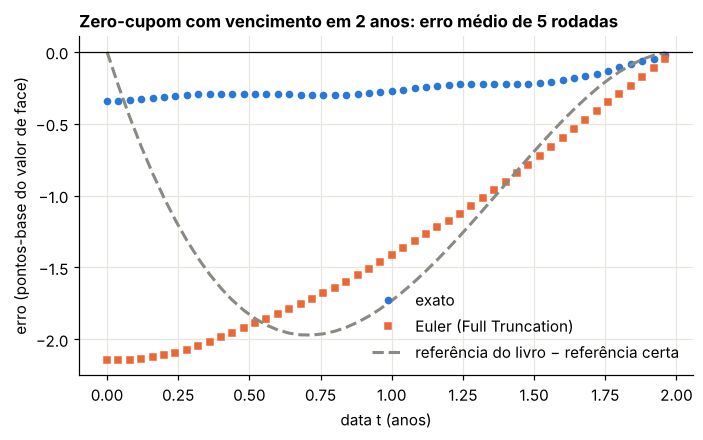

OK — o esquema exato tem erro muito menor que o do Euler
OK — o Euler tem viés para baixo, como no livro
OK — a desigualdade de Jensen: E[P(r_t)] > P(E[r_t]) em todas as datas t > 0


In [7]:
fig, ax = plt.subplots()
ax.plot(ts, 1e4 * (est["exato"] - ref_certa).mean(0), "o", ms=4, color=AZUL, label="exato")
ax.plot(ts, 1e4 * (est["euler"] - ref_certa).mean(0), "s", ms=4, color=LARANJA, label="Euler (Full Truncation)")
ax.plot(ts, -1e4 * gap, "--", color=CINZA, label="referência do livro − referência certa")
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("data t (anos)")
ax.set_ylabel("erro (pontos-base do valor de face)")
ax.set_title("Zero-cupom com vencimento em 2 anos: erro médio de 5 rodadas")
ax.legend()
plt.show()

ok(abs(tab3.loc[0, "erro médio (pb)"]) < 0.25 * abs(tab3.loc[1, "erro médio (pb)"]) + 3 * tab3.loc[0, "erro-padrão (pb)"],
   "o esquema exato tem erro muito menor que o do Euler")
ok(tab3.loc[1, "erro médio (pb)"] < -3 * tab3.loc[1, "erro-padrão (pb)"],
   "o Euler tem viés para baixo, como no livro")
ok(np.all(gap[1:] > 0), "a desigualdade de Jensen: E[P(r_t)] > P(E[r_t]) em todas as datas t > 0")

**O que aprendemos.**

* O viés do Euler existe e é para baixo, como diz o livro, mas é pequeno: um a dois pontos-base do valor de face.
* O "exato" ainda carrega o pequeno erro da regra do trapézio na integral de $r$: a transição de $r$ é exata, a integral não.
* Ele é da **mesma ordem** que o erro da referência usada nas Figuras 10.2 e 10.3. Contra a referência do livro, o exato parece ter viés para cima e o Euler parece quase sem viés. Para comparar esquemas, a referência precisa ser mais exata que a diferença que se quer medir.

---
## 4. O modelo de Heston: discretizar a variância

**Livro: §10.3**

### 4.1 O índice

Com juros constantes, sob $Q$:

$$dS_t = rS_t\,dt + \sqrt{v_t}\,S_t\,dZ^1_t, \qquad dv_t = \kappa_v(\theta_v - v_t)\,dt + \sigma_v\sqrt{v_t}\,dZ^2_t, \qquad dZ^1dZ^2 = \rho\,dt.$$

Pelo Itô, $d\ln S = (r - \tfrac12 v)\,dt + \sqrt{v}\,dZ^1$. O log-Euler (10.6) congela $v$ no **início** do passo:

$$S_t = S_s\exp\!\Big((r - \tfrac12 v_s)\Delta t + \sqrt{v_s}\sqrt{\Delta t}\,z^1_t\Big).$$

Para correlacionar, usamos Cholesky: $z^2_t = \rho\,z^1_t + \sqrt{1 - \rho^2}\,\varepsilon_t$.

### 4.2 Cinco esquemas com sete nomes

A transição exata da Seção 2 não se correlaciona facilmente com $z^1$. Por isso o livro usa esquemas de Euler, que só diferem no que fazem quando $\tilde x$ fica negativo. Na notação de Lord, Koekkoek e van Dijk (2006), o passo é

$$\tilde x_t = f_1(\tilde x_s) + \kappa\big(\theta - f_2(\tilde x_s)\big)\Delta t + \sigma\sqrt{f_3(\tilde x_s)}\sqrt{\Delta t}\,z_t, \qquad x_t = f_3(\tilde x_t),$$

| Esquema | $f_1$ | $f_2$ | $f_3$ |
|---|---|---|---|
| Absorption (A) | $x^+$ | $x^+$ | $x^+$ |
| Reflection (R) | $\lvert x\rvert$ | $\lvert x\rvert$ | $\lvert x\rvert$ |
| Higham-Mao (HM) | $x$ | $x$ | $\lvert x\rvert$ |
| Partial Truncation (PT) | $x$ | $x$ | $x^+$ |
| Full Truncation (FT) | $x$ | $x^+$ | $x^+$ |

O livro lista mais dois: **Truncation** e **Simple Reflection**. Olhando o código (§10.6.3), Truncation recalcula a partir de $x_s = \max(0, \tilde x_s)$ com drift e raiz em $x_s$: é exatamente o Absorption. Simple Reflection faz o mesmo com $\lvert\cdot\rvert$: é exatamente o Reflection. O laboratório confere isso trajetória a trajetória. (No Reflection, diferenças de arredondamento da ordem de $10^{-17}$ podem crescer um pouco quando $x$ passa muito perto de zero, porque a derivada de $\sqrt{x}$ explode ali; por isso a tolerância é maior nesse caso.)

> **Nota.** O código do livro para o Reflection usa `xh[t-1]` sem valor absoluto no primeiro termo, ao contrário da fórmula impressa e de Lord et al. Aqui seguimos a fórmula.

In [8]:
ESQUEMAS = ["FT", "PT", "A", "R", "HM"]


def passo_v(esquema, xh, kappa, theta, sigma, dt, z):
    """Um passo dos esquemas de Lord et al. Recebe x̃_s, devolve (x_t, x̃_t)."""
    if esquema == "FT":
        p = np.maximum(xh, 0); xh = xh + kappa * (theta - p) * dt + sigma * np.sqrt(p * dt) * z
        return np.maximum(xh, 0), xh
    if esquema == "PT":
        p = np.maximum(xh, 0); xh = xh + kappa * (theta - xh) * dt + sigma * np.sqrt(p * dt) * z
        return np.maximum(xh, 0), xh
    if esquema == "A":
        p = np.maximum(xh, 0); xh = p + kappa * (theta - p) * dt + sigma * np.sqrt(p * dt) * z
        return np.maximum(xh, 0), xh
    if esquema == "R":
        p = np.abs(xh); xh = p + kappa * (theta - p) * dt + sigma * np.sqrt(p * dt) * z
        return np.abs(xh), xh
    if esquema == "HM":
        p = np.abs(xh); xh = xh + kappa * (theta - xh) * dt + sigma * np.sqrt(p * dt) * z
        return np.abs(xh), xh
    raise ValueError(esquema)


# Os dois esquemas "extras" do livro, transcritos do código da §10.6.3
def truncation_livro(x, kappa, theta, sigma, dt, z):
    return np.maximum(0, x + kappa * (theta - x) * dt + np.sqrt(x) * sigma * z * np.sqrt(dt))


def simple_reflection_livro(x, kappa, theta, sigma, dt, z):
    return np.abs(x + kappa * (theta - x) * dt + np.sqrt(x) * sigma * z * np.sqrt(dt))


rng = np.random.default_rng(4)
kappa, theta, sigma, dt = 0.75, 0.02, 0.3, 1 / 50
Z = rng.standard_normal((100, 20_000))
xa = xh_a = np.full(20_000, 0.04); xt_ = xt0 = np.full(20_000, 0.04)
xr = xh_r = np.full(20_000, 0.04); xs_ = np.full(20_000, 0.04)
for z in Z:
    xa, xh_a = passo_v("A", xh_a, kappa, theta, sigma, dt, z)
    xt_ = truncation_livro(xt_, kappa, theta, sigma, dt, z)
    xr, xh_r = passo_v("R", xh_r, kappa, theta, sigma, dt, z)
    xs_ = simple_reflection_livro(xs_, kappa, theta, sigma, dt, z)
print("fração de passos com x̃ < 0 no Absorption:", f3(np.mean(xa == 0)))
ok(np.allclose(xa, xt_, rtol=0, atol=1e-14), "Truncation do livro coincide com Absorption em todas as trajetórias")
print("maior diferença Reflection × Simple Reflection:", f"{np.abs(xr - xs_).max():.1e}")
ok(np.abs(xr - xs_).max() < 1e-8, "Simple Reflection do livro coincide com Reflection, a menos de arredondamento")

fração de passos com x̃ < 0 no Absorption: 0,052
OK — Truncation do livro coincide com Absorption em todas as trajetórias
maior diferença Reflection × Simple Reflection: 1.2e-14
OK — Simple Reflection do livro coincide com Reflection, a menos de arredondamento


### 4.3 Um viés escondido no código do livro: olhar para a frente

No código da §10.6.3, o passo do índice é

```python
S[t] = S[t - 1] * np.exp((r - 0.5 * v[t]) * dt + np.sqrt(v[t]) * ran[row] * sdt - bias)
```

com `v[t]`, a variância do **fim** do passo, e não `v[t - 1]`. O problema é que `v[t]` foi gerada com o choque $z^2_t$, que é correlacionado com o mesmo $z^1_t$ que multiplica a raiz. A propriedade da Seção 1.1 se perde: $\sqrt{v_t}$ não é mais independente de $z^1_t$.

**Quanto vale o viés, passo a passo.** Expandindo a raiz em primeira ordem em torno de $v_s$:

$$\sqrt{v_t} \approx \sqrt{v_s} + \frac{v_t - v_s}{2\sqrt{v_s}} \approx \sqrt{v_s} + \frac{\sigma_v\sqrt{v_s}\sqrt{\Delta t}\,z^2_t}{2\sqrt{v_s}} = \sqrt{v_s} + \tfrac12\sigma_v\sqrt{\Delta t}\,z^2_t.$$

Então

$$\mathbb{E}\big[\sqrt{v_t}\sqrt{\Delta t}\,z^1_t\big] \approx \tfrac12\sigma_v\,\Delta t\,\mathbb{E}[z^2_tz^1_t] = \tfrac12\rho\,\sigma_v\,\Delta t.$$

Cada passo ganha um drift espúrio de $\tfrac12\rho\sigma_v\Delta t$ em $\ln S$, que **não some** quando $\Delta t \to 0$: somando $M$ passos, o drift extra é $\tfrac12\rho\sigma_vT$. A previsão é

$$\mathbb{E}[S_T] \approx S_0e^{rT}\,e^{\rho\sigma_vT/2}.$$

Isso não é um erro de discretização, que diminui com $\Delta t$: é um erro de **modelo**. O esquema converge para o processo errado (é a diferença entre as integrais de Itô e de Stratonovich, Módulo 4).

Com o `bias` do casamento de momentos, que subtrai a média amostral de $\sqrt{v_t}\sqrt{\Delta t}\,z^1_t$ a cada passo, o drift espúrio é removido. Por isso a Tabela 10.1 do livro mostra um efeito tão dramático do casamento de momentos (erro quadrático médio de cerca de 3,7 para cerca de 0,001): ele está consertando o bug.

### Laboratório 4 — O viés previsto e o observado

Usamos os quatro painéis de Medvedev e Scaillet (2010) do livro, $\theta_v = 0{,}02$, $S_0 = 100$, $r = 5\%$, 50 passos por ano, e simulamos o índice com `v[t-1]` (certo) e com `v[t]` (livro).

In [9]:
PAINEIS = [(0.01, 1.50, 0.15, 0.10),     # (v0, κ_v, σ_v, ρ)
           (0.04, 0.75, 0.30, 0.10),
           (0.04, 1.50, 0.30, 0.10),
           (0.04, 1.50, 0.15, -0.50)]
THETA_V, S0, r = 0.02, 100.0, 0.05
STRIKES = np.array([90.0, 100.0, 110.0])
PRAZOS = [1 / 12, 1.0, 2.0]


def heston_mc(painel, T, M0, I, rng, esquema="FT", adiante=False, mm=False, anti=True):
    """Simula S_T no Heston. adiante=True reproduz o v[t] do livro; mm=True aplica
    o casamento de momentos dos normais e a correção de drift do livro."""
    v0, kappa, sigma, rho = painel
    M = max(int(round(M0 * T)), 1)
    dt = T / M
    if anti:
        Z = rng.standard_normal((2, M, I // 2))
        Z = np.concatenate([Z, -Z], axis=2)
    else:
        Z = rng.standard_normal((2, M, I))
    if mm:
        Z = (Z - Z.mean()) / Z.std()
    v = np.full(I, v0); vh = v.copy(); x = np.zeros(I)
    for t in range(M):
        z1 = Z[0, t]
        z2 = rho * z1 + np.sqrt(1 - rho**2) * Z[1, t]
        v_novo, vh = passo_v(esquema, vh, kappa, THETA_V, sigma, dt, z2)
        vu = v_novo if adiante else v
        choque = np.sqrt(vu * dt) * z1
        if mm:
            choque = choque - choque.mean()
        x += (r - 0.5 * vu) * dt + choque
        v = v_novo
    return S0 * np.exp(x)


rng = np.random.default_rng(5)
linhas = []
for i, p in enumerate(PAINEIS):
    for T in (1.0, 2.0):
        fwd = S0 * np.exp(r * T)
        prev = fwd * (np.exp(p[3] * p[2] * T / 2) - 1)
        e_certo = heston_mc(p, T, 50, 100_000, rng).mean() - fwd
        e_livro = heston_mc(p, T, 50, 100_000, rng, adiante=True).mean() - fwd
        linhas.append((i + 1, T, p[3] * p[2], prev, e_livro, e_certo))
tab4 = pd.DataFrame(linhas, columns=["painel", "T", "ρσ_v", "erro previsto de E[S_T]",
                                     "erro com v[t] (livro)", "erro com v[t−1]"])
tabela(tab4)

,painel,T,ρσ_v,erro previsto de E[S_T],erro com v[t] (livro),erro com v[t−1]
0,1,"1,000","0,015","0,791","0,793","0,008"
1,1,"2,000","0,015","1,670","1,579","-0,011"
2,2,"1,000","0,030","1,589","1,555","-0,068"
3,2,"2,000","0,030","3,366","3,101","-0,006"
4,3,"1,000","0,030","1,589","1,601","0,065"
5,3,"2,000","0,030","3,366","3,289","0,017"
6,4,"1,000","-0,075","-3,869","-3,919","0,014"
7,4,"2,000","-0,075","-7,986","-8,049","0,021"


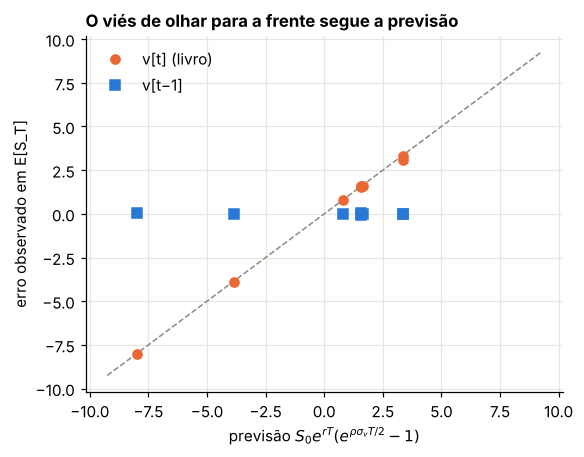

OK — o erro com v[t] fica a até 25% da previsão ½ρσ_vT em todos os casos
OK — com v[t−1], o erro de E[S_T] é pequeno (menos de 25 centavos)


In [10]:
fig, ax = plt.subplots(figsize=(5.6, 4.2))
lim = 1.15 * np.abs(tab4[["erro previsto de E[S_T]", "erro com v[t] (livro)"]]).values.max()
ax.plot([-lim, lim], [-lim, lim], "--", color=CINZA, lw=1)
ax.plot(tab4["erro previsto de E[S_T]"], tab4["erro com v[t] (livro)"], "o", color=LARANJA, label="v[t] (livro)")
ax.plot(tab4["erro previsto de E[S_T]"], tab4["erro com v[t−1]"], "s", color=AZUL, label="v[t−1]")
ax.set_xlabel(r"previsão $S_0e^{rT}(e^{\rho\sigma_vT/2}-1)$")
ax.set_ylabel("erro observado em E[S_T]")
ax.set_title("O viés de olhar para a frente segue a previsão")
ax.legend()
plt.show()

rel = tab4["erro com v[t] (livro)"] / tab4["erro previsto de E[S_T]"]
ok(np.all((rel > 0.75) & (rel < 1.25)), "o erro com v[t] fica a até 25% da previsão ½ρσ_vT em todos os casos")
ok(np.all(np.abs(tab4["erro com v[t−1]"]) < 0.25), "com v[t−1], o erro de E[S_T] é pequeno (menos de 25 centavos)")

O viés com `v[t]` chega a 8 unidades num índice de 100 (painel 4, $T = 2$), e a previsão de primeira ordem o explica bem. Com `v[t-1]` sobra algo de poucos centavos, vindo da truncação e do ruído.

Há uma razão estrutural para o esquema certo acertar a média: com $v_s$ conhecido no início do passo e $z^1_t$ independente dele,

$$\mathbb{E}\big[S_t\,\big|\,\mathcal F_s\big] = S_s\,e^{(r - v_s/2)\Delta t}\,\mathbb{E}\big[e^{\sqrt{v_s\Delta t}\,z^1}\big] = S_s\,e^{(r - v_s/2)\Delta t}\,e^{v_s\Delta t/2} = S_s\,e^{r\Delta t}.$$

O preço descontado simulado é uma martingal **exata**, qualquer que seja $\Delta t$ e qualquer que seja o esquema da variância.

---
## 5. O teste de Medvedev e Scaillet

**Livro: §10.3 (Tabelas 10.1 e 10.2, Figura 10.4)**

O livro avalia calls e puts europeias nos quatro painéis, com $T \in \{1/12, 1, 2\}$ e $K \in \{90, 100, 110\}$: 36 opções de cada tipo. A referência é o preço de Fourier (aqui, Lewis). Um preço "erra" se viola os dois critérios de acurácia ao mesmo tempo.

### Laboratório 5 — Reproduzir a Tabela 10.1 e ver o que muda

Rodamos 3 vezes cada configuração, com $I = 50.000$ trajetórias (antitéticas) e 50 passos por ano, sobre as 72 opções (calls e puts das mesmas trajetórias): 216 avaliações por linha. As puts usam o payoff simulado, não a paridade, como no livro.

In [11]:
REFS = {}
for i, p in enumerate(PAINEIS):
    for T in PRAZOS:
        C = call_heston(STRIKES, T, r, p[0], p[1], THETA_V, p[2], p[3])
        REFS[i, T] = (C, C - S0 + STRIKES * np.exp(-r * T))


def teste_ms(rng, rodadas=3, I=50_000, M0=50, **kw):
    erros, refs = [], []
    for _ in range(rodadas):
        for i, p in enumerate(PAINEIS):
            for T in PRAZOS:
                S = heston_mc(p, T, M0, I, rng, **kw)
                df = np.exp(-r * T)
                C = df * np.maximum(S[:, None] - STRIKES, 0).mean(0)
                P = df * np.maximum(STRIKES - S[:, None], 0).mean(0)
                erros += list(C - REFS[i, T][0]) + list(P - REFS[i, T][1])
                refs += list(REFS[i, T][0]) + list(REFS[i, T][1])
    erros, refs = np.array(erros), np.array(refs)
    return erros, refs


configs = [("FT", "v[t−1]", False, dict(esquema="FT")),
           ("PT", "v[t−1]", False, dict(esquema="PT")),
           ("A",  "v[t−1]", False, dict(esquema="A")),
           ("R",  "v[t−1]", False, dict(esquema="R")),
           ("HM", "v[t−1]", False, dict(esquema="HM")),
           ("FT", "v[t−1]", True,  dict(esquema="FT", mm=True)),
           ("FT", "v[t] (livro)", False, dict(esquema="FT", adiante=True)),
           ("FT", "v[t] (livro)", True,  dict(esquema="FT", adiante=True, mm=True))]
rng = np.random.default_rng(250000)
t0 = time.time()
linhas, caixas = [], {}
for esq, idx, mm, kw in configs:
    e, ref = teste_ms(rng, **kw)
    n_err = int((~acerto(e, ref)).sum())
    linhas.append((esq, idx, "sim" if mm else "não", n_err, len(e), e.mean(), np.mean(e**2)))
    caixas[f"{esq}\n{idx.split()[0]}\nMM={'s' if mm else 'n'}"] = e
tab5 = pd.DataFrame(linhas, columns=["variância", "índice usa", "casamento de momentos",
                                     "erros", "opções", "erro médio", "EQM"])
tabela(tab5)
print(f"tempo: {time.time() - t0:.1f} s")

,variância,índice usa,casamento de momentos,erros,opções,erro médio,EQM
0,FT,v[t−1],não,9,216,"0,007","0,002"
1,PT,v[t−1],não,12,216,"0,012","0,002"
2,A,v[t−1],não,23,216,"0,022","0,003"
3,R,v[t−1],não,42,216,"0,046","0,010"
4,HM,v[t−1],não,21,216,"0,025","0,004"
5,FT,v[t−1],sim,4,216,"0,003","0,001"
6,FT,v[t] (livro),não,174,216,"0,036","2,286"
7,FT,v[t] (livro),sim,5,216,"-0,011","0,001"


tempo: 24.9 s


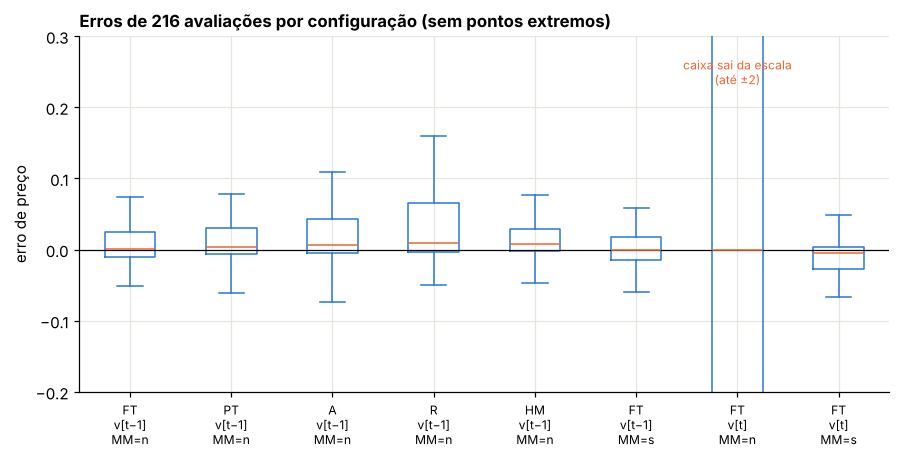

OK — o código do livro sem casamento de momentos tem EQM acima de 1, como na Tabela 10.1
OK — e erra a maioria das opções
OK — com v[t−1], o Full Truncation acerta sem nenhuma correção (EQM < 0,01)
OK — e erra no máximo 5% das opções
OK — o casamento de momentos conserta o código do livro
OK — o Reflection é pior que o Full Truncation


In [12]:
fig, ax = plt.subplots(figsize=(9.5, 4.2))
ax.boxplot(list(caixas.values()), tick_labels=list(caixas.keys()), showfliers=False,
           medianprops=dict(color=LARANJA), boxprops=dict(color=AZUL), whiskerprops=dict(color=AZUL),
           capprops=dict(color=AZUL))
ax.axhline(0, color="black", lw=0.8)
ax.set_ylim(-0.2, 0.3)
ax.annotate("caixa sai da escala\n(até ±2)", xy=(7, 0.27), ha="center", va="top", fontsize=8, color=LARANJA)
ax.set_ylabel("erro de preço")
ax.set_title("Erros de 216 avaliações por configuração (sem pontos extremos)")
ax.tick_params(axis="x", labelsize=8)
plt.show()

eqm = tab5.set_index(["variância", "índice usa", "casamento de momentos"])["EQM"]
erros = tab5.set_index(["variância", "índice usa", "casamento de momentos"])["erros"]
ok(eqm["FT", "v[t] (livro)", "não"] > 1.0, "o código do livro sem casamento de momentos tem EQM acima de 1, como na Tabela 10.1")
ok(erros["FT", "v[t] (livro)", "não"] > 0.6 * 216, "e erra a maioria das opções")
ok(eqm["FT", "v[t−1]", "não"] < 0.01, "com v[t−1], o Full Truncation acerta sem nenhuma correção (EQM < 0,01)")
ok(erros["FT", "v[t−1]", "não"] <= 0.05 * 216, "e erra no máximo 5% das opções")
ok(eqm["FT", "v[t] (livro)", "sim"] < 0.01, "o casamento de momentos conserta o código do livro")
ok(eqm["R", "v[t−1]", "não"] > eqm["FT", "v[t−1]", "não"], "o Reflection é pior que o Full Truncation")

**O que aprendemos.**

* A linha "v[t] (livro), sem casamento de momentos" reproduz a Tabela 10.1: a grande maioria das opções erradas e EQM acima de 2, que é a média entre calls e puts (o livro relata cerca de 3,7 para as calls e 0,9 para as puts).
* Com `v[t-1]`, o Full Truncation sem correção nenhuma já fica perto do nível que o livro só atinge com casamento de momentos. O "efeito impressionante" da Figura 10.4 é, quase todo, o conserto do bug.
* Entre os esquemas, Full Truncation e Partial Truncation são os melhores; Higham-Mao e Absorption ficam atrás; Reflection é o pior. Todos erram para cima. Refletir ou absorver no zero muda a variância de forma sistemática: refletir transforma um valor negativo num positivo do mesmo tamanho, o que infla a variância média. É o resultado de Lord et al. (2006), que o livro cita: o Full Truncation é o vencedor.

---
## 6. Redução de variância

**Livro: §10.3 e §10.4 (equação 10.8)**

O viés se combate com esquemas melhores e mais passos. O **ruído** se combate com mais trajetórias, cujo custo é alto (o erro-padrão cai como $1/\sqrt I$), ou com técnicas de redução de variância.

### 6.1 Variáveis antitéticas

Para cada vetor de choques $z$, simulamos também $-z$. O estimador de um par é $\bar Y = (Y + Y')/2$, e

$$\text{Var}(\bar Y) = \frac{\sigma^2_Y}{2}\big(1 + \text{Corr}(Y, Y')\big).$$

Comparado com duas trajetórias independentes ($\sigma^2_Y/2$), o ganho depende de $\text{Corr}(Y, Y') < 0$. Para payoffs **monótonos** no choque (uma call bem dentro do dinheiro) a correlação é muito negativa e o ganho é grande; para payoffs simétricos, como um straddle, pode não haver ganho nenhum.

### 6.2 Casamento de momentos

Depois de gerar os normais, impomos média amostral 0 e desvio amostral 1: $z \leftarrow (z - \bar z)/s_z$. O livro faz isso sobre o array inteiro, e ainda subtrai, a cada passo, a média amostral do choque do índice. Essa última correção força $\frac1I\sum_i S_{t,i} = $ média de $S_s e^{r\Delta t}$, uma ideia conhecida como **martingal empírica** (Duan e Simonato, 1998).

Duas observações. As trajetórias deixam de ser independentes, e o erro-padrão usual deixa de valer. E, como vimos, essa correção também apaga erros de modelo, como o da Seção 4.3, o que é útil, mas esconde o problema.

### 6.3 Variáveis de controle

Seja $Y$ o payoff descontado que queremos e $X$ outro, simulado nas mesmas trajetórias, cuja média $\mathbb{E}[X]$ **conhecemos**. O estimador

$$\hat Y_{CV} = \frac1I\sum_i\big(Y_i - \lambda(X_i - \mathbb{E}[X])\big)$$

é não viesado para qualquer $\lambda$. Sua variância é $\sigma^2_Y - 2\lambda\,\text{Cov}(X, Y) + \lambda^2\sigma^2_X$, mínima em

$$\lambda^* = \frac{\text{Cov}(X, Y)}{\text{Var}(X)}, \qquad \text{Var}(\hat Y_{CV}) = \frac{\sigma^2_Y}{I}\big(1 - \text{Corr}(X, Y)^2\big).$$

Com correlação de 0,99, a variância cai 50 vezes: o mesmo que 50 vezes mais trajetórias. O livro usa a put europeia como controle da americana (10.8), com $\lambda = 1$.

### Laboratório 6 — Quanto cada técnica reduz o ruído

Para a call de $K = 100$, $T = 1$, painel 4, repetimos 100 vezes cada configuração com $I = 10.000$ e medimos o desvio-padrão das estimativas. Como controle, usamos o próprio $e^{-rT}S_T$, cuja média é $S_0$ exatamente (a martingal da Seção 4.3), com $\lambda^*$ estimado na amostra.

In [13]:
p, T, Kc, I, rep = PAINEIS[3], 1.0, 100.0, 10_000, 100
ref_c = REFS[3, 1.0][0][1]
df = np.exp(-r * T)
rng = np.random.default_rng(6)
resultado = {}
for nome, kw, cv in [("simples", dict(anti=False), False),
                     ("antitéticas", dict(anti=True), False),
                     ("casamento de momentos", dict(anti=False, mm=True), False),
                     ("antitéticas + momentos", dict(anti=True, mm=True), False),
                     ("controle S_T", dict(anti=False), True),
                     ("antitéticas + controle", dict(anti=True), True)]:
    est = []
    for _ in range(rep):
        S = heston_mc(p, T, 50, I, rng, **kw)
        Y = df * np.maximum(S - Kc, 0)
        if cv:
            X = df * S
            lam = np.cov(X, Y)[0, 1] / X.var()
            Y = Y - lam * (X - S0)
        est.append(Y.mean())
    est = np.array(est)
    resultado[nome] = (est.mean() - ref_c, est.std(ddof=1))
tab6 = pd.DataFrame([(k, v[0], v[1], (resultado["simples"][1] / v[1]) ** 2) for k, v in resultado.items()],
                    columns=["técnica", "viés médio", "desvio-padrão", "ganho equivalente em trajetórias"])
tabela(tab6)

,técnica,viés médio,desvio-padrão,ganho equivalente em trajetórias
0,simples,"0,002","0,118","1,000"
1,antitéticas,"0,003","0,083","2,042"
2,casamento de momentos,"0,001","0,063","3,463"
3,antitéticas + momentos,"0,016","0,087","1,819"
4,controle S_T,"0,009","0,052","5,111"
5,antitéticas + controle,"0,005","0,067","3,108"


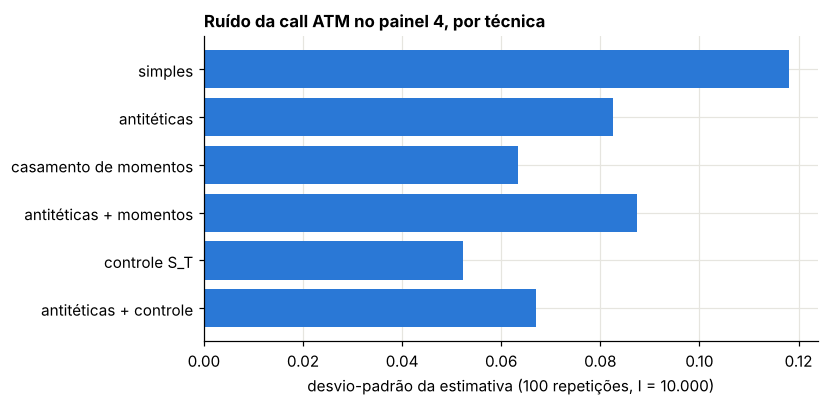

OK — as antitéticas reduzem a variância de uma call (payoff monótono no choque)
OK — o controle S_T rende mais que 2,5 vezes mais trajetórias
OK — para esta call, o controle supera as antitéticas
OK — o estimador com controle não tem viés detectável


In [14]:
fig, ax = plt.subplots(figsize=(7.2, 3.6))
ax.barh(tab6["técnica"][::-1], tab6["desvio-padrão"][::-1], color=AZUL)
ax.set_xlabel("desvio-padrão da estimativa (100 repetições, I = 10.000)")
ax.set_title("Ruído da call ATM no painel 4, por técnica")
plt.show()

g = tab6.set_index("técnica")["ganho equivalente em trajetórias"]
ok(g["antitéticas"] > 1.5, "as antitéticas reduzem a variância de uma call (payoff monótono no choque)")
ok(g["controle S_T"] > 2.5, "o controle S_T rende mais que 2,5 vezes mais trajetórias")
ok(g["controle S_T"] > g["antitéticas"], "para esta call, o controle supera as antitéticas")
ok(abs(resultado["antitéticas + controle"][0]) < 3 * resultado["antitéticas + controle"][1] / np.sqrt(rep) + 0.01,
   "o estimador com controle não tem viés detectável")

Para esta call, o controle $S_T$ é mais eficaz que as antitéticas, mas os dois **não se somam**: atacam a mesma coisa, a parte do payoff que é linear nos choques. As antitéticas cancelam essa parte por simetria; o controle $S_T$, por regressão. O casamento de momentos rende algo parecido com as antitéticas, porque também corrige o primeiro momento dos choques. Combinadas, aqui renderam até menos que o controle sozinho. As técnicas só se complementam quando miram partes diferentes do payoff. (Os desvios-padrão de 100 repetições têm cerca de 7% de imprecisão; a ordem entre as linhas próximas pode mudar com outra semente.)

---
## 7. Americanas no Heston com juros CIR

**Livro: §10.4 e §10.6.4 (Tabelas 10.3 e 10.4)**

### 7.1 O modelo e o algoritmo

O modelo agora tem três fatores: $S$ (Heston), $v$ (raiz quadrada) e $r$ (CIR, com $r_0 = 4\%$, $\kappa_r = 0{,}3$, $\theta_r = 4\%$, $\sigma_r = 0{,}1$), com $Z^3$ independente. O livro avalia puts americanas com $T \in \{1/12, 1/4, 1/2\}$ e $K \in \{90, 100, 110\}$ nos quatro painéis: 36 opções, contra as referências de Medvedev e Scaillet (LSM com 1 milhão de trajetórias e 500 passos).

O algoritmo é o LSM do Módulo 9, com quatro ingredientes:

1. **Índice**: log-Euler com a média trapezoidal dos juros, $\ln S_t = \ln S_s + \big(\tfrac{r_s + r_t}{2} - \tfrac{v}{2}\big)\Delta t + \sqrt{v}\sqrt{\Delta t}\,z^1_t$.
2. **Regressão**: só trajetórias dentro do dinheiro, com 11 funções de base: $1, r, v, S, r^2, v^2, S^2, vr, Sr, Sv, Svr$.
3. **Desconto**: trajetória a trajetória, pela média trapezoidal de $r$.
4. **Controle**: a put europeia simulada nas mesmas trajetórias, com $\lambda = 1$ em (10.8). Sua média é tomada como o preço de Heston com a taxa constante $\bar r = -\ln P(0, T)/T$. Pelo Módulo 11, essa aproximação erra muito pouco em prazos de até seis meses.

> **Mais um detalhe do código do livro.** Na §10.6.4, a matriz de correlação tem $\rho$ na posição (0, 1). A linha 0 é a dos juros, a linha 1 a do índice, a linha 2 a da variância. Ou seja: a correlação $\rho$ é posta entre **juros e índice**, e a variância fica independente do índice. Como o controle europeu vem da fórmula de Heston **com** $\rho$, o estimador (10.8) "contrabandeia" a correlação de volta: o resultado é aproximadamente americana($\rho = 0$) + [europeia($\rho$) − europeia($\rho = 0$)]. Como o prêmio de exercício antecipado é pouco sensível a $\rho$, o erro passa despercebido no teste.

### Laboratório 7 — 36 puts americanas contra Medvedev e Scaillet

In [15]:
BENCH_MS = np.array(((0.0001, 1.0438, 9.9950, 0.0346, 1.7379, 9.9823, 0.2040, 2.3951, 9.9726),
                     (0.0619, 2.1306, 10.0386, 0.5303, 3.4173, 10.4271, 1.1824, 4.4249, 11.0224),
                     (0.0592, 2.1138, 10.0372, 0.4950, 3.3478, 10.3825, 1.0752, 4.2732, 10.8964),
                     (0.0787, 2.1277, 10.0198, 0.6012, 3.4089, 10.2512, 1.2896, 4.4103, 10.6988)))
R0, KR, THR, SR = 0.04, 0.3, 0.04, 0.1
PRAZOS_AM = [1 / 12, 0.25, 0.5]


def trajetorias_ft(x0, kappa, theta, sigma, dt, Z):
    x = np.empty((Z.shape[0] + 1, Z.shape[1])); x[0] = x0; xh = np.full(Z.shape[1], x0)
    for t in range(Z.shape[0]):
        x[t + 1], xh = passo_v("FT", xh, kappa, theta, sigma, dt, Z[t])
    return x


def lsm_svsi(painel, T, M, I, rng, controle=True, como_livro=False):
    """Puts americanas (K = 90, 100, 110) no Heston + CIR.
    controle: False (sem), True (λ = 1, como no livro) ou "otimo" (λ* estimado).
    como_livro=True usa v[t] e a correlação entre juros e índice, como na §10.6.4."""
    v0, kv, sv, rho = painel
    dt = T / M
    Z = rng.standard_normal((3, M, I // 2)); Z = np.concatenate([Z, -Z], axis=2)
    zs = Z[0]
    if como_livro:
        zv, zr = Z[1], rho * Z[0] + np.sqrt(1 - rho**2) * Z[2]
    else:
        zv, zr = rho * Z[0] + np.sqrt(1 - rho**2) * Z[1], Z[2]
    rr = trajetorias_ft(R0, KR, THR, SR, dt, zr)
    v = trajetorias_ft(v0, kv, THETA_V, sv, dt, zv)
    x = np.zeros((M + 1, I))
    for t in range(M):
        vu = v[t + 1] if como_livro else v[t]
        x[t + 1] = x[t] + ((rr[t] + rr[t + 1]) / 2 - vu / 2) * dt + np.sqrt(vu * dt) * zs[t]
    S = S0 * np.exp(x)
    fd = np.exp(-(rr[1:] + rr[:-1]) / 2 * dt)        # fator de desconto de cada passo
    B0T = zcb_cir(R0, KR, THR, SR, T)
    rbar = -np.log(B0T) / T
    precos = []
    for K in STRIKES:
        h = np.maximum(K - S, 0)
        V = h[-1].copy()
        for t in range(M - 1, 0, -1):
            V = V * fd[t]
            itm = h[t] > 0
            if itm.sum() > 20:
                s_, v_, r_ = S[t, itm], v[t, itm], rr[t, itm]
                X = np.column_stack([np.ones_like(s_), r_, v_, s_, r_**2, v_**2, s_**2,
                                     v_ * r_, s_ * r_, s_ * v_, s_ * v_ * r_])
                cont = X @ np.linalg.lstsq(X, V[itm], rcond=None)[0]
                idx = np.where(itm)[0][h[t, itm] > cont]
                V[idx] = h[t, idx]
        Y = V * fd[0]
        if controle:
            P_eur = call_heston(K, T, rbar, v0, kv, THETA_V, sv, rho)[0] - S0 + K * B0T
            X_eur = np.prod(fd, axis=0) * h[-1]
            lam = 1.0 if controle is True else np.cov(X_eur, Y)[0, 1] / X_eur.var()
            Y = Y - lam * (X_eur - P_eur)
        precos.append(max(Y.mean(), K - S0))           # exercício em t = 0
    return np.array(precos)


def teste_americanas(rng, **kw):
    out = np.zeros((4, 9))
    for i, p in enumerate(PAINEIS):
        for j, T in enumerate(PRAZOS_AM):
            out[i, 3 * j:3 * j + 3] = lsm_svsi(p, T, 25, 35_000, rng, **kw)
    return out


rng = np.random.default_rng(250000)
t0 = time.time()
res_cv = teste_americanas(rng)
t_cv = time.time() - t0
res_sem = teste_americanas(rng, controle=False)
res_livro = teste_americanas(rng, como_livro=True)
res_livro_sem = teste_americanas(rng, como_livro=True, controle=False)

linhas = []
for nome, res in [("certo, com controle", res_cv), ("certo, sem controle", res_sem),
                  ("como no livro, com controle", res_livro), ("como no livro, sem controle", res_livro_sem)]:
    e = res - BENCH_MS
    linhas.append((nome, int((~acerto(e, BENCH_MS)).sum()), 36, e.mean(), np.abs(e).mean(), np.mean(e**2)))
tab7 = pd.DataFrame(linhas, columns=["configuração", "erros", "opções", "erro médio", "erro absoluto médio", "EQM"])
tabela(tab7)
print(f"tempo com controle: {t_cv:.1f} s para 36 opções ({t_cv / 36:.3f} s por opção)")

# ruído: 12 repetições das três puts do painel 4 com T = 1/2
dp = {}
for nome, c in [("sem controle", False), ("λ = 1 (livro)", True), ("λ* estimado", "otimo")]:
    a = np.array([lsm_svsi(PAINEIS[3], 0.5, 25, 35_000, rng, controle=c) for _ in range(12)])
    dp[nome] = a.std(axis=0, ddof=1)
tab7b = pd.DataFrame(dp, index=[f"K = {k:.0f}" for k in STRIKES]).T
print("desvio-padrão em 12 repetições (painel 4, T = 1/2):")
tabela(tab7b)

,configuração,erros,opções,erro médio,erro absoluto médio,EQM
0,"certo, com controle",0,36,"-0,006","0,014","0,000"
1,"certo, sem controle",0,36,"0,002","0,014","0,000"
2,"como no livro, com controle",0,36,"0,004","0,013","0,000"
3,"como no livro, sem controle",9,36,"-0,009","0,042","0,004"


tempo com controle: 3.9 s para 36 opções (0.110 s por opção)


desvio-padrão em 12 repetições (painel 4, T = 1/2):


,K = 90,K = 100,K = 110
sem controle,"0,013","0,023","0,029"
λ = 1 (livro),"0,008","0,029","0,031"
λ* estimado,"0,008","0,015","0,023"


,painel,T,K,Medvedev-Scaillet,LSM com controle,erro
27,4,1/12,"90,000","0,079","0,079","0,000"
28,4,1/12,"100,000","2,128","2,132","0,004"
29,4,1/12,"110,000","10,020","10,000","-0,020"
30,4,1/4,"90,000","0,601","0,605","0,004"
31,4,1/4,"100,000","3,409","3,391","-0,018"
32,4,1/4,"110,000","10,251","10,234","-0,017"
33,4,1/2,"90,000","1,290","1,287","-0,002"
34,4,1/2,"100,000","4,410","4,369","-0,041"
35,4,1/2,"110,000","10,699","10,620","-0,079"


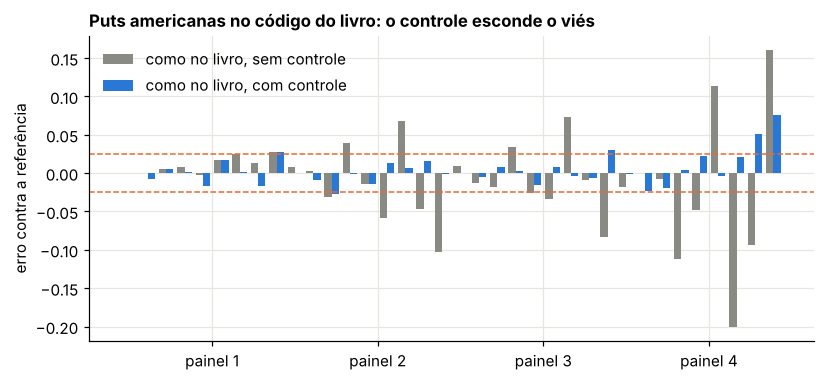

OK — com controle, no máximo 3 das 36 puts ficam fora do critério
OK — com o índice certo, mesmo sem controle o teste passa
OK — na put fora do dinheiro, o controle com λ = 1 reduz o ruído em mais de 30%
OK — sem controle, o código do livro erra muito mais
OK — com controle, o código do livro passa no teste: o controle esconde os dois desvios


In [16]:
det = pd.DataFrame({"painel": np.repeat([1, 2, 3, 4], 9),
                    "T": np.tile(np.repeat(["1/12", "1/4", "1/2"], 3), 4),
                    "K": np.tile(STRIKES, 12),
                    "Medvedev-Scaillet": BENCH_MS.ravel(),
                    "LSM com controle": res_cv.ravel(),
                    "erro": (res_cv - BENCH_MS).ravel()})
tabela(det[det["painel"] == 4])

fig, ax = plt.subplots(figsize=(8.5, 3.6))
xs = np.arange(36)
ax.bar(xs - 0.2, (res_livro_sem - BENCH_MS).ravel(), 0.4, color=CINZA, label="como no livro, sem controle")
ax.bar(xs + 0.2, (res_livro - BENCH_MS).ravel(), 0.4, color=AZUL, label="como no livro, com controle")
ax.axhline(0.025, ls="--", color=LARANJA, lw=1); ax.axhline(-0.025, ls="--", color=LARANJA, lw=1)
ax.set_xticks(np.arange(4.5, 36, 9), [f"painel {i}" for i in range(1, 5)])
ax.set_ylabel("erro contra a referência")
ax.set_title("Puts americanas no código do livro: o controle esconde o viés")
ax.legend()
plt.show()

err = tab7.set_index("configuração")
ok(err.loc["certo, com controle", "erros"] <= 3, "com controle, no máximo 3 das 36 puts ficam fora do critério")
ok(err.loc["certo, sem controle", "erros"] <= 3, "com o índice certo, mesmo sem controle o teste passa")
ok(tab7b.loc["λ = 1 (livro)", "K = 90"] < 0.7 * tab7b.loc["sem controle", "K = 90"],
   "na put fora do dinheiro, o controle com λ = 1 reduz o ruído em mais de 30%")
ok(err.loc["como no livro, sem controle", "EQM"] > 10 * err.loc["certo, sem controle", "EQM"],
   "sem controle, o código do livro erra muito mais")
ok(err.loc["como no livro, com controle", "erros"] <= 6,
   "com controle, o código do livro passa no teste: o controle esconde os dois desvios")

**O que aprendemos.**

* Com o índice certo, o LSM acerta as 36 puts com ou sem controle. Não é o controle que faz o teste passar.
* O ganho de ruído do controle depende da opção. Na put fora do dinheiro ele é claro. Dentro do dinheiro, muitas trajetórias são exercidas cedo, e o payoff americano fica pouco correlacionado com o europeu no vencimento; com $\lambda = 1$, o controle pode até **aumentar** o ruído, porque $\text{Var}(Y - X) = \sigma_Y^2 + \sigma_X^2 - 2\,\text{Cov}$ supera $\sigma_Y^2$ quando $\text{Cov} < \sigma_X^2/2$. O $\lambda^*$ estimado protege contra isso dentro de cada rodada (com 12 repetições, os desvios-padrão da tabela ainda têm uns 20% de imprecisão).
* No código do livro, sem controle, nove das 36 puts saem do critério e o EQM é dez vezes maior: é o viés de `v[t]` de novo, menor porque os prazos são curtos. A Tabela 10.4 conclui que o controle é "de importância primordial". Em boa parte, isso acontece porque o controle cancela esse viés: americana e europeia são simuladas nas mesmas trajetórias e erram quase igual.
* Lição geral: um controle absorve qualquer erro que afete a americana e a europeia da mesma forma. Um teste que só compara preços com controle não diagnostica esses erros; o teste europeu da Seção 5 diagnostica.

---
## 8. Síntese

| Fonte de erro | Como aparece | Como reduzir |
|---|---|---|
| Discretização (viés fraco) | cai como $\Delta t$ | mais passos; esquema melhor; transição exata quando existe |
| Tratamento do zero na variância | viés que depende do esquema | Full Truncation (ou esquemas como o QE de Andersen) |
| Erro de modelo no código (`v[t]`) | viés que **não** cai com $\Delta t$ | avaliar coeficientes no início do passo; conferir a martingal $e^{-rT}\mathbb{E}[S_T] = S_0$ |
| Ruído estatístico | cai como $1/\sqrt I$ | antitéticas; casamento de momentos; variáveis de controle |
| Referência errada | erros aparentes | referência mais exata que a diferença medida |

A conferência mais barata e mais útil de qualquer simulação de preços é a da martingal: o preço descontado do ativo simulado deve ter média $S_0$. Ela teria apontado o problema da Seção 4.3 em uma linha.

## 9. Erratas e notas sobre o capítulo 10

| Onde | O quê |
|---|---|
| §10.6.3 e §10.6.4, processo do índice | usa `v[t]` (fim do passo) em vez de `v[t-1]`; cria o drift espúrio $\tfrac12\rho\sigma_v$ por unidade de tempo em $\ln S$, que não diminui com $\Delta t$ |
| Tabela 10.1 e Figura 10.4 | o salto de precisão atribuído ao casamento de momentos é, em sua maior parte, a correção de drift (`bias`) desfazendo o problema acima; com `v[t-1]` não há salto |
| §10.3, lista de esquemas | "Truncation" coincide com "Absorption" e "Simple Reflection" com "Reflection": são cinco esquemas, não sete |
| §10.2, Figuras 10.2 e 10.3 | a referência em $t > 0$ é $P(\mathbb{E}[r_t])$, mas a média de Monte Carlo estima $\mathbb{E}[P(r_t)]$; a diferença (Jensen) é da ordem do viés do Euler que se quer mostrar |
| §10.6.2, esquema exato | `np.ramdom.chisquare` (erro de digitação) |
| §10.6.4, correlação | $\rho$ posto entre juros e índice, e não entre variância e índice; o controle europeu disfarça o efeito |
| §10.4, controle | a média do controle usa Heston com taxa constante $\bar r$, uma aproximação (Módulo 11), pequena para prazos de até seis meses |
| §10.2 | a transição por qui-quadrado não central é clássica (Feller, 1951; Cox, Ingersoll e Ross, 1985); Broadie e Kaya (2006) a usam na simulação exata do Heston |
| Scripts | Python 2 (`xrange`, `print` sem parênteses; `I / 2` vira real no Python 3) |

## 10. Exercícios

**Exercício 1.** Mostre que, no esquema ingênuo (10.7), $\mathbb{E}[S_t\,|\,S_s] = S_se^{r\Delta t}$, mas $S_t$ pode ser negativo. Qual a probabilidade de um passo ficar negativo com $\sigma = 0{,}3$ e $\Delta t = 1/50$?

<details><summary>Solução</summary>

A média sai de $\mathbb{E}[z] = 0$. O passo fica negativo se $z < -e^{r\Delta t}/(\sigma\sqrt{\Delta t}) \approx -1/(0{,}3 \cdot 0{,}141) \approx -23{,}6$: probabilidade da ordem de $10^{-123}$, desprezível. O problema do esquema não é o sinal, é a forma da distribuição.
</details>

**Exercício 2.** Refaça o Laboratório 4 com 100 e 200 passos por ano. O que acontece com o erro de `v[t]`? E com o de `v[t-1]`?

<details><summary>Solução</summary>

O erro de `v[t]` praticamente não muda: é $\tfrac12\rho\sigma_vT$, independente de $\Delta t$. O de `v[t-1]`, que vem da truncação e do ruído, diminui ou fica no nível do ruído. Essa é a forma prática de distinguir erro de modelo de erro de discretização.
</details>

**Exercício 3.** Prove a fórmula da variância das antitéticas e mostre que, para $Y = (S_T - K)^2$ num mundo BSM com $K = S_0e^{rT}$ e $\sigma\sqrt T$ pequeno, quase não há ganho.

<details><summary>Solução</summary>

$\text{Var}((Y + Y')/2) = \tfrac14(\sigma^2 + \sigma^2 + 2\text{Cov}) = \tfrac{\sigma^2}{2}(1 + \text{Corr})$. Com $\sigma\sqrt T$ pequeno, $S_T - K \approx K\sigma\sqrt T z$, e $Y \approx K^2\sigma^2Tz^2$, função par de $z$: $Y' = Y$, correlação 1, ganho nenhum (o par custa o dobro e rende o mesmo).
</details>

**Exercício 4.** No Laboratório 6, troque o controle $S_T$ pela call europeia de BSM com $\sigma = \sqrt{\theta_v}$, simulada com os mesmos choques $z^1$ e volatilidade constante. O ganho é maior ou menor?

<details><summary>Solução</summary>

Depende do painel. A call BSM tem forma de payoff idêntica, o que aumenta a correlação nos estados em que a call paga; mas a variância simulada no Heston difere de $\theta_v$, o que a reduz. Nos painéis com $\sigma_v$ pequeno, o ganho tende a superar o do controle $S_T$. Meça e compare $\text{Corr}(X, Y)^2$.
</details>

**Exercício 5 (desafio).** Implemente o esquema QE de Andersen (2008) para a variância e compare com o Full Truncation no teste da Seção 5 com 10 passos por ano.

<details><summary>Solução</summary>

O QE casa os dois primeiros momentos condicionais da Seção 2.2: se $\psi = \text{Var}/\text{média}^2 \le 1{,}5$, usa $v_t = a(b + z)^2$; senão, uma mistura de massa em zero com uma exponencial. Com 10 passos por ano, o QE costuma errar bem menos que o Full Truncation, porque respeita a distribuição de $v$ mesmo com passos longos.
</details>

In [17]:
print(f"Módulo 12 concluído: {_checks['n']} verificações aprovadas.")

Módulo 12 concluído: 32 verificações aprovadas.
